# Etapa 3 - Feature Engineering

- Nessa etapa, a série de vendas diárias construída na etapa 2 é preparada para os dois grupos de modelos do projeto:
  - **Modelos estatísticos de séries temporais** (ARIMA e SARIMA), que trabalham diretamente com a sequência histórica de vendas.
  - **Modelos de machine learning** (XGBoost e LightGBM), que não enxergam a ordem dos dados e, por isso, precisam que a informação temporal seja transformada em colunas (features).
- Antes de criar as features, são definidos o horizonte de previsão e a divisão da base em treino, validação e teste. Essa ordem garante que nenhuma informação do futuro seja utilizada para construir as features ou treinar os modelos (data leakage).

In [1]:
# Importando as bibliotecas
import pandas as pd
import seaborn as sns
# Configurando o matplotlib
%matplotlib inline                              
import matplotlib.pyplot as plt
import numpy as np
import holidays

In [2]:
# Carregando a série temporal de vendas diárias construída na etapa 2
df = pd.read_csv(r'../data/sales_ts_daily.csv', index_col = 'sale_date', parse_dates = True)

# Definindo a frequência diária do índice
df = df.asfreq('D')

In [3]:
# Avaliando as informações do dataframe
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 592 entries, 2017-01-05 to 2018-08-19
Freq: D
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   order_units  592 non-null    int64
dtypes: int64(1)
memory usage: 9.2 KB


In [4]:
# Visualizando a base
df.head(5)

,order_units
sale_date,
2017-01-05,32
2017-01-06,4
2017-01-07,5
2017-01-08,4
2017-01-09,6


### Horizonte de previsão e divisão da base

- O horizonte de previsão adotado é de **28 dias** (4 semanas completas). Esse horizonte atende ao objetivo do projeto de apoiar o planejamento logístico e financeiro de curto prazo, e por ser múltiplo de 7 todos os dias da semana aparecem o mesmo número de vezes no período previsto.
- A base é dividida em três conjuntos, sempre respeitando a ordem cronológica (sem embaralhar os dados):
  - **Teste**: as últimas 4 semanas da série (23/07/2018 a 19/08/2018). Esse conjunto simula o ambiente de produção e só será utilizado ao final, para avaliar os modelos já definidos.
  - **Validação**: as 4 semanas anteriores ao teste (25/06/2018 a 22/07/2018), utilizadas para escolher as configurações de cada modelo (ordens do ARIMA/SARIMA e hiperparâmetros dos modelos de ML).
  - **Treino**: todo o histórico anterior à validação.

In [5]:
# Definindo o horizonte de previsão e as datas de corte
horizonte = 28
inicio_validacao = '2018-06-25'
inicio_teste = '2018-07-23'

# Criando coluna indicando o conjunto de cada registro
df['split'] = 'treino'
df.loc[inicio_validacao:, 'split'] = 'validacao'
df.loc[inicio_teste:, 'split'] = 'teste'

In [6]:
# Avaliando o período e o número de dias de cada conjunto
df.reset_index().groupby('split', sort = False)['sale_date'].agg(['min', 'max', 'count'])

,min,max,count
split,,,
treino,2017-01-05,2018-06-24,536
validacao,2018-06-25,2018-07-22,28
teste,2018-07-23,2018-08-19,28


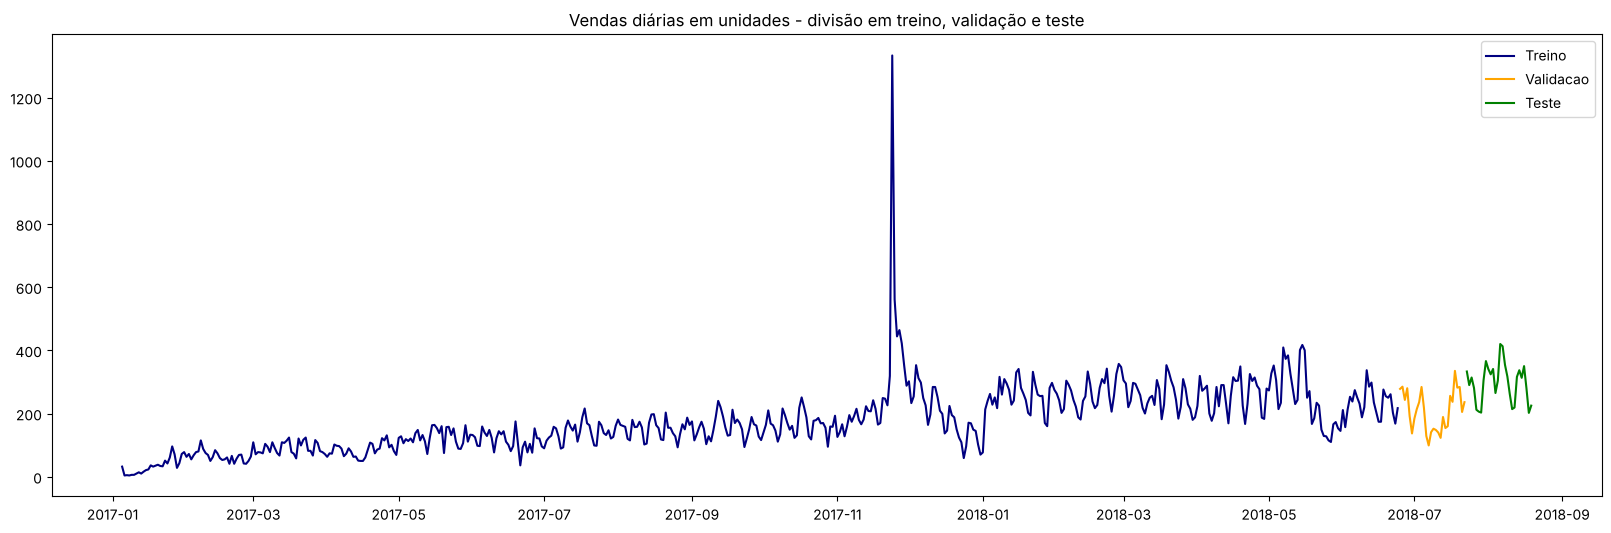

In [7]:
# Plotando a divisão da base
fig, ax = plt.subplots(figsize = (20,6))

for split, cor in zip(['treino', 'validacao', 'teste'], ['navy', 'orange', 'green']):
    ax.plot(df.loc[df['split'] == split, 'order_units'], label = split.capitalize(), color = cor)
plt.title('Vendas diárias em unidades - divisão em treino, validação e teste')
plt.legend()

plt.show()

- Na etapa de modelagem, cada modelo é treinado com a base de treino e avaliado na validação para a escolha das configurações. Em seguida, o modelo escolhido é treinado novamente com treino + validação e faz a previsão das 4 semanas de teste, simulando uma previsão real feita em 22/07/2018.

### Variáveis de eventos

- Na análise exploratória foram identificados eventos que alteram o padrão de vendas: os feriados nacionais, a Black Friday de 2017, o período de festas de fim de ano e a greve dos caminhoneiros de maio de 2018.
- Essas variáveis são comuns aos dois grupos de modelos. Por serem datas de calendário (conhecidas com antecedência), elas podem ser utilizadas como variáveis explicativas sem risco de vazamento de dados.
- Os eventos foram definidos da seguinte forma:
  - `feriado`: feriados nacionais, obtidos pela biblioteca [holidays](https://github.com/vacanza/holidays).
  - `black_friday`: 24/11/2017, o maior pico de vendas da série.
  - `pos_black_friday`: 25/11/2017 a 28/11/2017, dias seguintes à Black Friday que ainda ficaram acima do padrão.
  - `fim_de_ano`: 21/12/2017 a 01/01/2018, período em que as vendas ficaram abaixo do padrão.
  - `greve_caminhoneiros`: 23/05/2018 a 31/05/2018, período em que a queda nas vendas, possivelmente causada pela greve, aparece na série.

In [ ]:
# Criando a variável de feriados nacionais
feriados = holidays.Brazil(years = df.index.year.unique())
df['feriado'] = df.index.isin(pd.to_datetime(list(feriados.keys()))).astype(int)

# Criando as variáveis dos demais eventos
df['black_friday'] = (df.index == '2017-11-24').astype(int)
df['pos_black_friday'] = ((df.index >= '2017-11-25') & (df.index <= '2017-11-28')).astype(int)
df['fim_de_ano'] = ((df.index >= '2017-12-21') & (df.index <= '2018-01-01')).astype(int)
df['greve_caminhoneiros'] = ((df.index >= '2018-05-23') & (df.index <= '2018-05-31')).astype(int)

# Lista com as variáveis de eventos
eventos = ['feriado', 'black_friday', 'pos_black_friday', 'fim_de_ano', 'greve_caminhoneiros']

In [ ]:
# Avaliando o número de dias marcados por evento em cada conjunto
df.groupby('split', sort = False)[eventos].sum()

,feriado,black_friday,pos_black_friday,fim_de_ano,greve_caminhoneiros
split,,,,,
treino,12,1,4,12,9
validacao,0,0,0,0,0
teste,0,0,0,0,0


In [ ]:
# Avaliando a média de vendas nos dias com e sem evento (somente na base de treino)
treino = df.loc[df['split'] == 'treino']

for evento in eventos:
    meses_evento = treino.loc[treino[evento] == 1].index.to_period('M').unique()          # Meses em que o evento ocorreu
    base_meses = treino.loc[treino.index.to_period('M').isin(meses_evento)]
    media_evento = base_meses.loc[base_meses[evento] == 1, 'order_units'].mean()
    media_demais = base_meses.loc[base_meses[evento] == 0, 'order_units'].mean()
    print('{}: média nos dias do evento = {:.0f} | média nos demais dias dos mesmos meses = {:.0f}'.format(evento, media_evento, media_demais))

feriado: média nos dias do evento = 137 | média nos demais dias dos mesmos meses = 205
black_friday: média nos dias do evento = 1333 | média nos demais dias dos mesmos meses = 242
pos_black_friday: média nos dias do evento = 473 | média nos demais dias dos mesmos meses = 249
fim_de_ano: média nos dias do evento = 118 | média nos demais dias dos mesmos meses = 249
greve_caminhoneiros: média nos dias do evento = 141 | média nos demais dias dos mesmos meses = 295


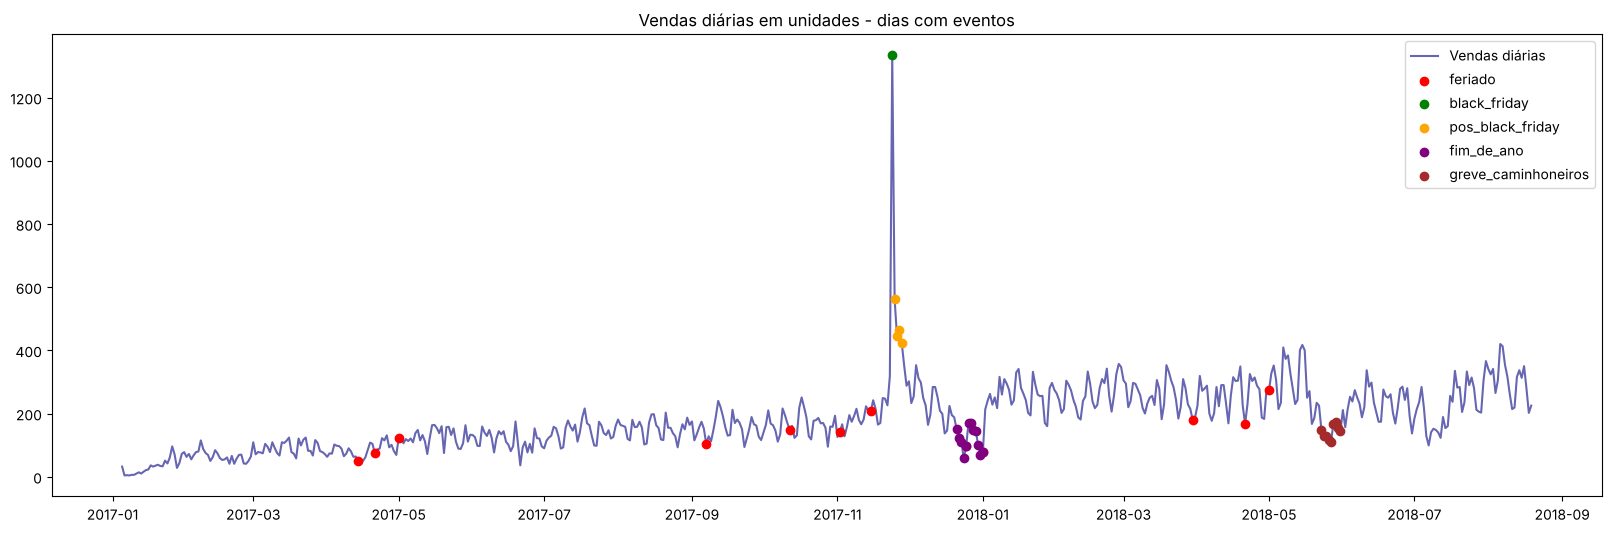

In [ ]:
# Plotando a série com os dias de evento destacados
fig, ax = plt.subplots(figsize = (20,6))

ax.plot(df['order_units'], color = 'navy', alpha = 0.6, label = 'Vendas diárias')
for evento, cor in zip(eventos, ['red', 'green', 'orange', 'purple', 'brown']):
    ax.scatter(df.loc[df[evento] == 1].index, df.loc[df[evento] == 1, 'order_units'], color = cor, label = evento, zorder = 3)
plt.title('Vendas diárias em unidades - dias com eventos')
plt.legend()

plt.show()

- Os feriados, o fim de ano e a greve dos caminhoneiros reduzem as vendas em relação à média do mês, enquanto a Black Friday e os dias seguintes elevam as vendas.
- Não há nenhum evento nos períodos de validação e de teste. Ainda assim, essas variáveis são importantes no treino: elas indicam aos modelos que esses dias são exceções, evitando que os picos e as quedas distorçam a tendência e a sazonalidade aprendidas.

### Feature Engineering para modelos de séries temporais

- Os modelos ARIMA e SARIMA modelam a própria série: os termos autorregressivos e de médias móveis já utilizam os valores e os erros passados, e as diferenciações (d e D) são aplicadas pelo próprio modelo. Por isso, não é necessário criar colunas de lags para esses modelos.
- Para esse grupo de modelos, são preparados dois itens:
  - **Transformação logarítmica** das vendas, já que a EDA mostrou que a amplitude da sazonalidade cresce junto com o nível da série (sazonalidade multiplicativa).
  - **Variáveis exógenas**, as variáveis de eventos criadas acima, que serão utilizadas na versão SARIMAX do modelo.

In [12]:
# Aplicando a transformação logarítmica nas vendas (a série não tem dias com venda zero)
df['log_units'] = np.log(df['order_units'])

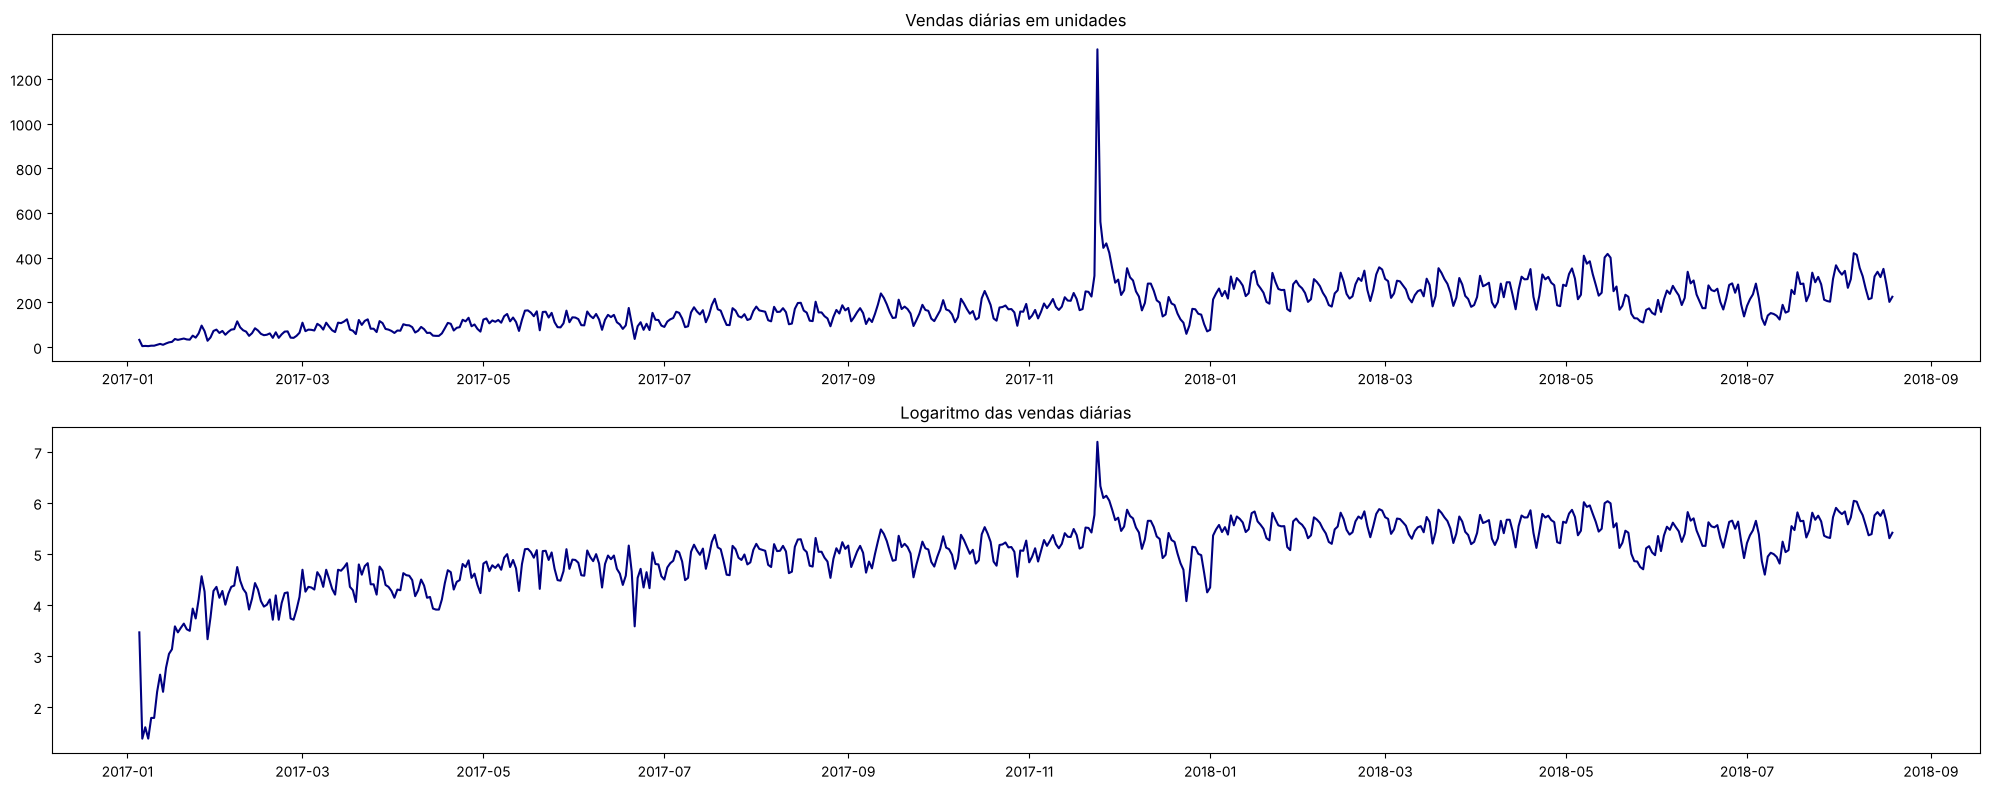

In [13]:
# Plotando a série original e a série transformada
fig, axs = plt.subplots(nrows = 2, ncols = 1, figsize = (20, 8), tight_layout = True)

axs[0].plot(df['order_units'], color = 'navy')
axs[0].set_title('Vendas diárias em unidades')
axs[1].plot(df['log_units'], color = 'navy')
axs[1].set_title('Logaritmo das vendas diárias')

plt.show()

In [14]:
# Definindo função para medir a relação entre o nível da série e a amplitude da variação semanal
def nivel_x_amplitude(serie):
    nivel = serie.rolling(7, center = True).mean()                 # Nível: média móvel centrada de 7 dias
    amplitude = (serie - nivel).abs()                              # Amplitude: desvio de cada dia em relação ao nível
    semanal = pd.DataFrame({'nivel' : nivel, 'amplitude' : amplitude}).resample('W').mean().dropna()
    return semanal['nivel'].corr(semanal['amplitude'])

# Avaliando a relação na base de treino, para a série completa e a partir de março de 2017
for coluna in ['order_units', 'log_units']:
    serie_treino = df.loc[df['split'] == 'treino', coluna]
    print('{}: correlação nível x amplitude = {:.2f} (série completa) | {:.2f} (a partir de mar/2017)'.format(
        coluna, nivel_x_amplitude(serie_treino), nivel_x_amplitude(serie_treino.loc['2017-03-01':])))

order_units: correlação nível x amplitude = 0.74 (série completa) | 0.72 (a partir de mar/2017)
log_units: correlação nível x amplitude = -0.39 (série completa) | -0.04 (a partir de mar/2017)


- Na série original, a amplitude da variação semanal tem correlação forte e positiva com o nível de vendas (0,74): quanto mais a plataforma vende, maior a diferença entre os dias da semana.
- Após a transformação logarítmica, essa relação praticamente desaparece a partir de março de 2017 (-0,04). Considerando a série completa, a correlação fica negativa (-0,39) por causa dos dois primeiros meses de 2017, quando as vendas eram muito baixas (de 4 a 30 unidades por dia) e pequenas variações absolutas viram grandes variações no logaritmo.
- Assim, a transformação logarítmica estabiliza a variação da série e será testada nos modelos estatísticos. As previsões feitas em log são convertidas de volta para unidades com a função exponencial antes do cálculo dos erros.

In [15]:
# Criando a base para os modelos de séries temporais
df_ts = df[['order_units', 'log_units'] + eventos + ['split']]

# Avaliando as informações da base
df_ts.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 592 entries, 2017-01-05 to 2018-08-19
Freq: D
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   order_units          592 non-null    int64  
 1   log_units            592 non-null    float64
 2   feriado              592 non-null    int64  
 3   black_friday         592 non-null    int64  
 4   pos_black_friday     592 non-null    int64  
 5   fim_de_ano           592 non-null    int64  
 6   greve_caminhoneiros  592 non-null    int64  
 7   split                592 non-null    str    
dtypes: float64(1), int64(6), str(1)
memory usage: 57.8 KB


### Feature Engineering para modelos de machine learning

- Os modelos de machine learning tratam cada linha de forma independente, sem considerar a ordem dos dados. Por isso, a dinâmica temporal da série precisa ser representada em colunas, com as features de calendário, de eventos e de vendas passadas.
- A regra principal para evitar o vazamento de dados é: **cada feature de um dia só pode usar informações conhecidas no momento em que a previsão é feita**. Como a previsão é feita de uma vez para os próximos 28 dias, o último dia previsto está 28 dias à frente da última venda conhecida. Assim, todas as features de vendas passadas usam apenas valores de **28 dias atrás ou mais**:
  - `lag_28`, `lag_35` e `lag_42`: vendas no mesmo dia da semana, 4, 5 e 6 semanas antes.
  - `rolling_mean_7_lag28` e `rolling_mean_28_lag28`: médias das vendas nos 7 e nos 28 dias encerrados 28 dias antes.
- Com essas features, as previsões das 4 semanas de teste usam apenas vendas registradas até 22/07/2018, exatamente como aconteceria em produção.

In [16]:
# Criando a base para os modelos de machine learning
df_ml = df[['order_units'] + eventos + ['split']].copy()

# Criando features de calendário
df_ml['month'] = df_ml.index.month
df_ml['day_of_week'] = df_ml.index.day_of_week
df_ml['day_of_month'] = df_ml.index.day

In [17]:
# Definindo função para criar as features de vendas passadas (somente valores de 28 dias atrás ou mais)
def criar_features_lag(serie, horizonte):
    features = pd.DataFrame(index = serie.index)
    features['lag_28'] = serie.shift(horizonte)                                  # Venda no mesmo dia da semana, 4 semanas antes
    features['lag_35'] = serie.shift(horizonte + 7)                              # Venda no mesmo dia da semana, 5 semanas antes
    features['lag_42'] = serie.shift(horizonte + 14)                             # Venda no mesmo dia da semana, 6 semanas antes
    features['rolling_mean_7_lag28'] = serie.shift(horizonte).rolling(7).mean()     # Média dos 7 dias encerrados 28 dias antes
    features['rolling_mean_28_lag28'] = serie.shift(horizonte).rolling(28).mean()   # Média dos 28 dias encerrados 28 dias antes
    return features

# Criando as features
features_lag = criar_features_lag(df_ml['order_units'], horizonte)
df_ml = pd.concat([df_ml, features_lag], axis = 1)

- Para confirmar que as features não utilizam informações do período de teste, as features são calculadas novamente com as vendas do teste apagadas. Se as features do teste forem iguais nas duas versões, nenhuma delas depende das vendas que se quer prever.

In [18]:
# Apagando as vendas do período de teste e recalculando as features
serie_sem_teste = df_ml['order_units'].copy()
serie_sem_teste.loc[inicio_teste:] = np.nan
features_sem_teste = criar_features_lag(serie_sem_teste, horizonte)

# Comparando as features do período de teste nas duas versões
iguais = features_lag.loc[inicio_teste:].equals(features_sem_teste.loc[inicio_teste:])
print('Features do teste iguais com e sem as vendas do teste: {}'.format(iguais))

Features do teste iguais com e sem as vendas do teste: True


In [19]:
# Avaliando os dados nulos gerados pelas defasagens
df_ml.isnull().sum()

order_units               0
feriado                   0
black_friday              0
pos_black_friday          0
fim_de_ano                0
greve_caminhoneiros       0
split                     0
month                     0
day_of_week               0
day_of_month              0
lag_28                   28
lag_35                   35
lag_42                   42
rolling_mean_7_lag28     34
rolling_mean_28_lag28    55
dtype: int64

- Os primeiros dias da série não têm histórico suficiente para o cálculo das defasagens e das médias móveis, gerando dados nulos. Esses valores não são preenchidos com o próximo valor ou com o último valor conhecido, já que isso poderia inserir informações do futuro na base. Por isso, esses dias são excluídos da base de machine learning, o que corresponde aos primeiros 55 dias da série (até o fim de fevereiro de 2017, período em que as vendas ainda eram muito baixas).

In [20]:
# Excluindo os dias sem histórico suficiente
df_ml = df_ml.dropna()

# Ajustando a ordem das colunas
cols = ['month', 'day_of_week', 'day_of_month',
        'lag_28', 'lag_35', 'lag_42', 'rolling_mean_7_lag28', 'rolling_mean_28_lag28',
        'feriado', 'black_friday', 'pos_black_friday', 'fim_de_ano', 'greve_caminhoneiros',
        'split', 'order_units']

df_ml = df_ml[cols]

In [21]:
# Avaliando as informações do dataframe
df_ml.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 537 entries, 2017-03-01 to 2018-08-19
Freq: D
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   month                  537 non-null    int32  
 1   day_of_week            537 non-null    int32  
 2   day_of_month           537 non-null    int32  
 3   lag_28                 537 non-null    float64
 4   lag_35                 537 non-null    float64
 5   lag_42                 537 non-null    float64
 6   rolling_mean_7_lag28   537 non-null    float64
 7   rolling_mean_28_lag28  537 non-null    float64
 8   feriado                537 non-null    int64  
 9   black_friday           537 non-null    int64  
 10  pos_black_friday       537 non-null    int64  
 11  fim_de_ano             537 non-null    int64  
 12  greve_caminhoneiros    537 non-null    int64  
 13  split                  537 non-null    str    
 14  order_units            537 non-null    int

In [22]:
# Visualizando a base
df_ml.head(3)

,month,day_of_week,day_of_month,lag_28,lag_35,lag_42,rolling_mean_7_lag28,rolling_mean_28_lag28,feriado,black_friday,pos_black_friday,fim_de_ano,greve_caminhoneiros,split,order_units
sale_date,,,,,,,,,,,,,,,
2017-03-01,3,2,1,63.0,61.0,32.0,64.428571,34.428571,0,0,0,0,0,treino,109
2017-03-02,3,3,2,72.0,96.0,35.0,61.000000,35.857143,0,0,0,0,0,treino,71
2017-03-03,3,4,3,55.0,71.0,38.0,58.714286,37.678571,0,0,0,0,0,treino,78


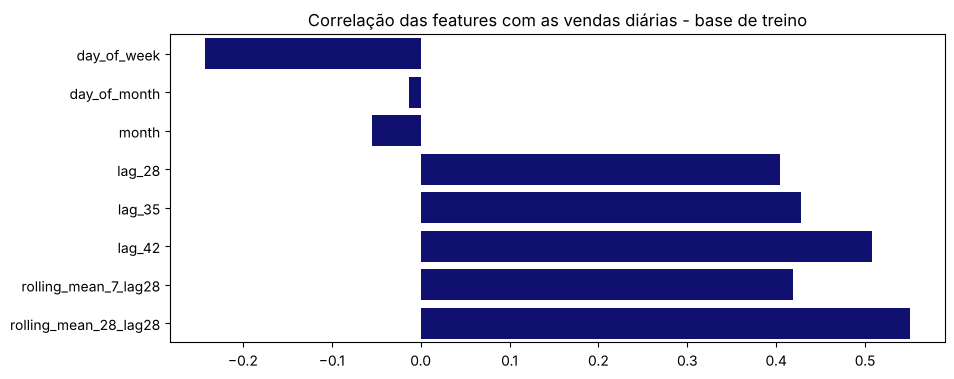

In [23]:
# Avaliando a correlação das features numéricas com o target (somente na base de treino)
features_num = ['day_of_week', 'day_of_month', 'month', 'lag_28', 'lag_35', 'lag_42', 'rolling_mean_7_lag28', 'rolling_mean_28_lag28']
corr = df_ml.loc[df_ml['split'] == 'treino', features_num + ['order_units']].corr()['order_units'].drop('order_units')

# Plotando resultados
fig, ax = plt.subplots(figsize = (10,4))

sns.barplot(x = corr.values, y = corr.index, color = 'navy', ax = ax)
ax.set_ylabel('')
plt.title('Correlação das features com as vendas diárias - base de treino')

plt.show()

- As features de vendas passadas têm correlação moderada com as vendas (entre 0,40 e 0,55), sendo a média dos 28 dias (`rolling_mean_28_lag28`) a mais correlacionada, já que representa o nível de vendas recente. O dia da semana tem correlação negativa, refletindo as vendas menores no fim de semana.
- A correlação mede apenas relações lineares; os modelos baseados em árvores (XGBoost e LightGBM) conseguem capturar relações não lineares, como o efeito de cada dia da semana separadamente. A importância real de cada feature será avaliada na etapa de modelagem.
- O dia do mês e o mês têm correlação próxima de zero. Elas são mantidas para que os modelos avaliem possíveis padrões ao longo do mês (como o recebimento de salários), mas devem ser revistas na modelagem: como a base tem menos de dois anos, cada mês aparece no máximo duas vezes no treino.

In [24]:
# Salvando as bases para a próxima etapa
df_ts.to_csv(r'../data/sales_db_03_ts.csv')
df_ml.to_csv(r'../data/sales_db_03_ml.csv')

### Conclusões da etapa de Feature Engineering

- **Objetivo da previsão**: total de unidades vendidas por dia, com horizonte de 28 dias.
- **Divisão da base**: treino até 24/06/2018, validação de 25/06/2018 a 22/07/2018 e teste de 23/07/2018 a 19/08/2018, sempre respeitando a ordem cronológica.
- **Eventos**: feriados nacionais, Black Friday, dias após a Black Friday, festas de fim de ano e greve dos caminhoneiros, utilizados pelos dois grupos de modelos.
- **Modelos de séries temporais** (`sales_db_03_ts.csv`): série original, série em logaritmo e variáveis de eventos como exógenas.
- **Modelos de machine learning** (`sales_db_03_ml.csv`): features de calendário, de eventos e de vendas passadas com defasagem mínima de 28 dias, confirmando que nenhuma feature do teste utiliza vendas do próprio período de teste.